In [1]:
from IPython.core.display import display, HTML
import scipy.constants as sc
from scipy.optimize import fsolve
from ipywidgets import interact, widgets
%matplotlib notebook

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as sc
plt.rcParams.update({
    "text.usetex": True,
    'text.latex.preamble': r"\usepackage{amsmath} \boldmath"
})
import os

print(os.getpid())
%cd ../

/tmp/ipykernel_10732/4235703534.py:1: DeprecationWarning: Importing display from IPython.core.display is deprecated since IPython 7.14, please import from IPython display
  from IPython.core.display import display, HTML


10732
/media/work/docs/codes/c++/QSVT_framework/simulations


/home/ivan/.pyenv/versions/3.11.0/lib/python3.11/site-packages/IPython/core/magics/osm.py:417: UserWarning: using dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [2]:
import XW_waves.xw_1d as xw
mix = xw.mix
mse = xw.mse
reload = mix.reload_module

/media/work/docs/codes/c++/QSVT_framework/simulations/pylib/mix.py:407: SyntaxWarning: "is" with a literal. Did you mean "=="?
  if len(possible_n_periods) is 0:


AttributeError: module 'numpy' has no attribute 'float'.
`np.float` was a deprecated alias for the builtin `float`. To avoid this error in existing code, use `float` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.float64` here.
The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:
    https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations

In [3]:
# choose the case to analyse
case_to_model = "ref"
path_case = "./XW_waves/ref-case"
path_results = "./XW_waves/ref-case/results"

In [4]:
# read .hdf5 files from different restarts:
reload(xw)

dd = {
    "path": path_case,
    "pname": "XW"
}
dd = mse.open_all(dd)
path_fig = path_case + "/" + dd["pname"] + "-" + case_to_model + "-"


--- Reading a file ./XW_waves/ref-case/XW_OUTPUT.hdf5...
Simulation has been performed  03-14-2022 12:18:33


In [5]:
# --- read output states at every time step ---
reload(xw)
mse.read_all_output_states(dd)

# --- read x-grid ---
x_qc = mse.get_x_grid(dd, "j") * 2 - 1
print("size of x-grid is", np.size(x_qc))


--- Reading a file ./XW_waves/ref-case/XW_OUTPUT.hdf5...
size of x-grid is 1024


In [6]:
# --- print initial states ---
reload(xw)

print("-----------------------------------------------------------------------------")
mse.print_initial_states(dd)
print("-----------------------------------------------------------------------------")

-----------------------------------------------------------------------------
--- Initial state ---
Registers: 
{'qb': 2, 'a': 2, 'aj': 2, 'ad': 3, 'd': 3, 'j': 10}

             7.071e-01   |00>|00>|00>|000>|101>|0111001100>
             7.071e-01   |00>|00>|00>|000>|101>|0111001101>
-----------------------------------------------------------------------------


In [7]:
# --- get amplitudes of variables ---
reload(xw)
vx = mse.get_amplitudes_xt(dd, {"d": 0}, "j")
vy = mse.get_amplitudes_xt(dd, {"d": 1}, "j")
Ex = mse.get_amplitudes_xt(dd, {"d": 2}, "j")
Ey = mse.get_amplitudes_xt(dd, {"d": 3}, "j")
Bz = mse.get_amplitudes_xt(dd, {"d": 4}, "j")
Q  = mse.get_amplitudes_xt(dd, {"d": 5}, "j")

Wv = np.abs(vx)**2 + np.abs(vy)**2
We = np.abs(Ex)**2 + np.abs(Ey)**2
Wb = np.abs(Bz)**2
Wq = np.abs(Q)**2
W = Wv + We + Wb + Wq

t = dd["t"]
beta = dd["qsp"]["norm"]

print("t_0 = {:0.3f}".format(t[-1]))

t_0 = 24.550


In [8]:
print("t0 = {:0.3f}".format(t[-1]*beta))
print("nt = {:d}".format(len(t)))
print("tau = {:0.3e}".format((t[1]-t[0])*beta))

t0 = 2.504
nt = 11
tau = 2.504e-01


In [9]:
t[-1]

24.55

In [10]:
# --- perform classical simulations ---
xw.mix.reload_module(xw)
dd_cl = xw.init(case_to_model)
print()
vars_cl = xw.launch(dd_cl)

x_cl = dd_cl["x-plot"]
t_cl = dd_cl["t-norm"]


vx_cl = vars_cl['vx']
vy_cl = vars_cl['vy']
Ex_cl = vars_cl['Ex']
Ey_cl = vars_cl['Ey']
Bz_cl = vars_cl['Bz']
Q_cl = vars_cl['Q']

Wv_cl = vars_cl["Wv"]
We_cl = vars_cl["We"]
Wb_cl = vars_cl["Wb"]
Wq_cl = vars_cl["Wq"]
W_cl = Wv_cl + We_cl + Wb_cl + Wq_cl

Simulation of a --- REF --- case

---------------------------------------------------------------------
--- Classical parameters ---
nqx, nx = 10, 1024
t, nt = 325.000, 1300
norm. time step: 2.504e-01
Courant number is: 7.604e-01

---------------------------------------------------------------------
--- QC parameters ---
QC time step: 2.455
QC normalization of a Hamiltonian matrix: 9.804
QC 1/norm_of_H: 1.020e-01
QC source init. value: 7.071e-01
QC time to simulate: 3186.270
QC number of time steps: 1298

Computation... id-t = 1200
Done
(sumx W[1] - sumx W[-1])/sumx W[1]: -8.681e-04


In [11]:
# -------------------------------------------------------------------
# --- Calculate energy integrated in space ---
# -------------------------------------------------------------------
nt = len(t)
Wt_v = np.array([np.sum(Wv[:,i]) for i in range(nt)])
Wt_e = np.array([np.sum(We[:,i]) for i in range(nt)])
Wt_b = np.array([np.sum(Wb[:,i]) for i in range(nt)])
Wt_q = np.array([np.sum(Wq[:,i]) for i in range(nt)])
Wt = np.array([np.sum(W[:,i]) for i in range(nt)])

nt_cl = len(t_cl)
Wt_v_cl = np.array([np.sum(Wv_cl[:,i]) for i in range(nt_cl)])
Wt_e_cl = np.array([np.sum(We_cl[:,i]) for i in range(nt_cl)])
Wt_b_cl = np.array([np.sum(Wb_cl[:,i]) for i in range(nt_cl)])
Wt_q_cl = np.array([np.sum(Wq_cl[:,i]) for i in range(nt_cl)])
Wt_cl = np.array([np.sum(W_cl[:,i]) for i in range(nt_cl)])

<IPython.core.display.Javascript object>


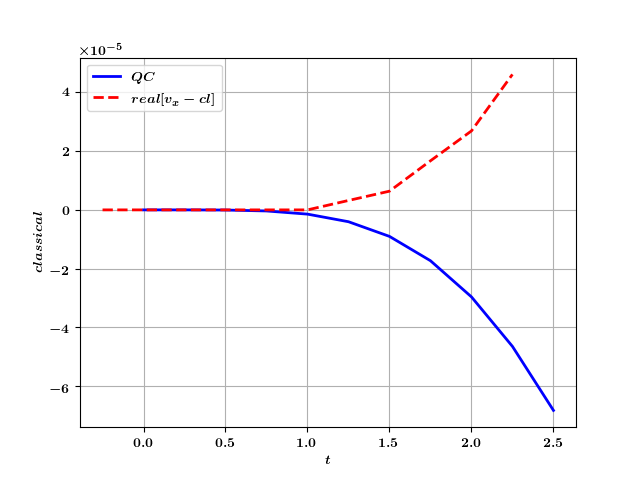

<IPython.core.display.Javascript object>


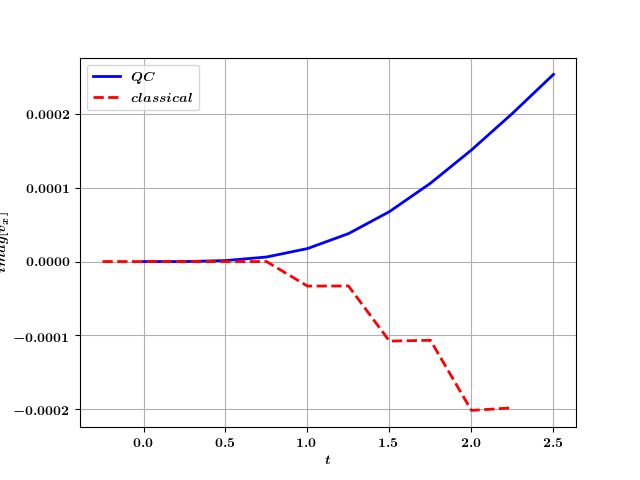

In [12]:
# ----------------------------------------------------------------------------------
# --- Compare signals in time at a particular x-point with classical data ---
# ----------------------------------------------------------------------------------
idx_point = vars_cl['ids-Q'][1] 

y_qc, y_cl, label_y = vx, vx_cl, "v_x"
# y_qc, y_cl, label_y = vy, vy_cl, "v_y"
# y_qc, y_cl, label_y = Ex, Ex_cl, "E_x"
# y_qc, y_cl, label_y = Ey, Ey_cl, "E_y"
# y_qc, y_cl, label_y = Bz, Bz_cl, "B_z"
# y_qc, y_cl, label_y = Q, Q_cl, "Q"


# y_qc, y_cl, label_y = Wv/beta, Wv_cl, "Wv"
# y_qc, y_cl, label_y = We/beta, We_cl, "We"
# y_qc, y_cl, label_y = Wb/beta, Wb_cl, "Wb"
# y_qc, y_cl, label_y = Wq/beta, Wq_cl, "Wq"
# y_qc, y_cl, label_y = W/beta, W_cl, "W"

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(
    t*beta, np.real(y_qc[idx_point,:]/beta), 
    color='b', 
#     marker="o", 
    linewidth = 2, linestyle='-', 
    label = "$QC$"
)
ax.plot(
    t_cl[0:len(t)], np.real(y_cl[idx_point,0:len(t)]), 
    color='r', 
#     marker="s", 
    linewidth = 2, linestyle='--',
    label = "$real[" + label_y + "-cl]$" 
)
plt.xlabel('$t$')
plt.ylabel("$classical$")
ax.legend()
plt.grid(True)
plt.show()
plt.savefig(path_fig + label_y + '-real.png')



fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(
    t*beta, np.imag(y_qc[idx_point,:]/beta), 
    color='b', 
#     marker="o", 
    linewidth = 2, linestyle='-', 
    label = "$QC$"
)
ax.plot(
    t_cl[0:len(t)], np.imag(y_cl[idx_point,0:len(t)]), 
    color='r', 
#     marker="s", 
    linewidth = 2, linestyle='--',
    label = "$classical$" 
)
plt.xlabel('$t$')
plt.ylabel("$imag["+ label_y +"]$")
ax.legend()
plt.grid(True)
plt.show()
plt.savefig(path_fig + label_y + '-imag.png')

<IPython.core.display.Javascript object>


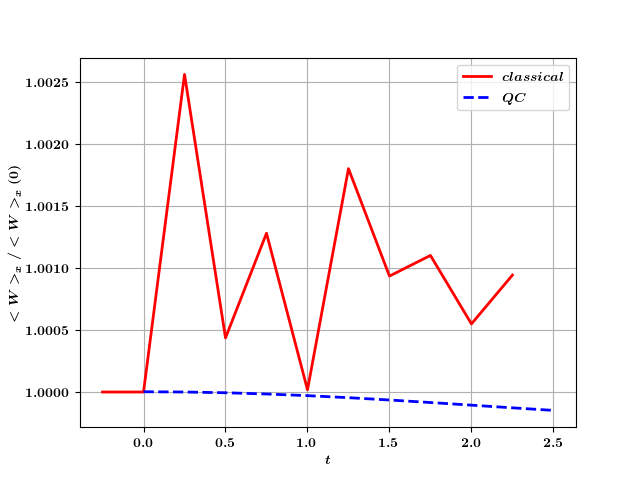

In [13]:
# ----------------------------------------------------------------------------------
# --- Compare energy integrated in time ---
# ----------------------------------------------------------------------------------
# y_qc, y_cl, label_y = Wt_v, Wt_v_cl, "<Wkin>_x"
# y_qc, y_cl, label_y = Wt_e, Wt_e_cl, "<We>_x"
# y_qc, y_cl, label_y = Wt_b, Wt_b_cl, "<Wb>_x"
# y_qc, y_cl, label_y = Wt_q, Wt_q_cl, "<Wq>_x"
y_qc, y_cl, label_y = Wt, Wt_cl, "<W>_x"

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(
    t_cl[0:len(t)], y_cl[0:len(t)]/Wt_cl[1],  
    color='r', 
    linewidth = 2, linestyle='-',
    label = "$classical$" 
)
ax.plot(
    t*beta, y_qc/Wt[1], 
    color='b',  
    linewidth = 2, linestyle='--', 
    label = "$QC$"
)
plt.xlabel('$t$')
plt.ylabel("$"+ label_y +"/<W>_x(0)$")
ax.legend()
plt.grid(True)
plt.show()
plt.savefig(path_fig + label_y + '.png')

In [14]:
# --- plot(x) at chosen t: ---
reload(xw)
def plot_x_at_t1(ax, f_plot, signal_name, flag_label_x):
    for i in range(len(t_points)):
        ax.plot(
            x_plot, 
            np.real(f_plot[:,t_points[i]]), 
            colors[i], 
            label = "t = {:0.1f}".format(t_norm[t_points[i]])
        )
    ax.axvline(x_plot[dd['id-x-L-cutoff'] ], color='b', linestyle = "--", linewidth = 1.0, label = "L-cutoff")
    ax.axvline(x_plot[dd['id-x-UH-res'] ], color='g', linestyle = "--", linewidth = 1.0, label = "UH-res")
        
    if flag_label_x: ax.set_xlabel('$x/r_0$')
    ax.set_ylabel('$' + signal_name + '$')
    ax.ticklabel_format(axis='y', style='sci', scilimits=[0,0])
    ax.grid(True)
    ax.legend()
    
y_qc, y_cl, label_y = vx, vx_cl, "\\xi_x"
# y_qc, y_cl, label_y = vy, vy_cl, "\\xi_y"
# y_qc, y_cl, label_y = Ex, Ex_cl, "E_x"
y_qc, y_cl, label_y = Ey, Ey_cl, "E_y"
# y_qc, y_cl, label_y = Bz, Bz_cl, "B_z"
# y_qc, y_cl, label_y = Wv/beta, Wv_cl, "W-kin"

# id_t_point = len(t)-1
id_t_point = 30


fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(x_qc, np.real(y_qc[:,id_t_point]/beta), "b-", label = "QC")
ax.plot(x_cl, np.real(y_cl[:,id_t_point]), "r--", label = "CL")
# ax.axvline(x_cl[dd['id-x-L-cutoff'] ], color='b', linestyle = "--", linewidth = 1.0, label = "L-cutoff")
# ax.axvline(x_cl[dd['id-x-UH-res'] ], color='g', linestyle = "--", linewidth = 1.0, label = "UH-res")
plt.xlabel('$x$')
plt.ylabel('$' + label_y + '$')
ax.ticklabel_format(axis='y', style='sci', scilimits=[0,0])
plt.title("t = {:0.1f}".format(t[id_t_point]))
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()
plt.savefig(path_fig + label_y + '-x-one-t.png')


fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(x_qc, np.imag(y_qc[:,id_t_point]/beta), "b-", label = "QC")
ax.plot(x_cl, np.imag(y_cl[:,id_t_point]), "r--", label = "CL")
# ax.axvline(x_cl[dd['id-x-L-cutoff'] ], color='b', linestyle = "--", linewidth = 1.0, label = "L-cutoff")
# ax.axvline(x_cl[dd['id-x-UH-res'] ], color='g', linestyle = "--", linewidth = 1.0, label = "UH-res")
plt.xlabel('$x$')
plt.ylabel('$' + label_y + '$')
ax.ticklabel_format(axis='y', style='sci', scilimits=[0,0])
plt.title("t = {:0.1f}".format(t[id_t_point]))
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

IndexError: index 30 is out of bounds for axis 1 with size 11

<IPython.core.display.Javascript object>


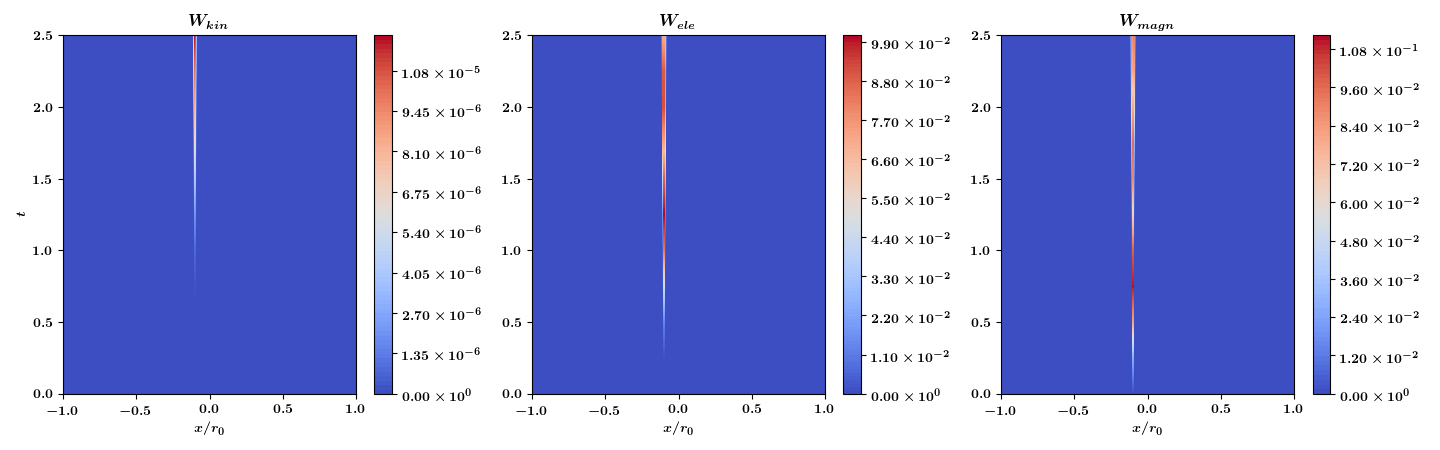

In [15]:
# *** plot(x,t) of W-components from QC ***
from matplotlib import ticker

cmap = 'seismic'
cmap = 'bwr'
cmap = 'jet'
cmap = 'coolwarm'

def fmt(x, pos):
    a, b = '{:.2e}'.format(x).split('e')
    b = int(b)
    return r'${} \times 10^{{{}}}$'.format(a, b)

def plot_xy(fig, axs, ax, f_plot, title, flag_label_x, flag_label_y):
    cs = ax.contourf(XX, YY, np.real(f_plot.T), levels=100, cmap=cmap)
    if flag_label_x: ax.set_xlabel('$x/r_0$')
    if flag_label_y: ax.set_ylabel('$t$')
    ax.set_title('$' + title + '$')
    fig.colorbar(cs, ax = ax, format=ticker.FuncFormatter(fmt))
    return cs


XX, YY = np.meshgrid(x_qc, t*beta)
fig, axs = plt.subplots(1, 3, figsize=(9.6 + 4.8,4.5))

cs1 = plot_xy(fig, axs, axs[0], Wv/beta**2, 'W_{kin}', True, True)
cs2 = plot_xy(fig, axs, axs[1], We/beta**2, 'W_{ele}', True, False)
cs3 = plot_xy(fig, axs, axs[2], Wb/beta**2, 'W_{magn}', True, False)

# fig.colorbar(cs2, ax = axs, format=ticker.FuncFormatter(fmt), shrink=0.5)

plt.tight_layout()
plt.show()

plt.savefig(path_fig + 'W-tx.png')

In [13]:
# -----------------------------------------------------------------
# --- SCAN on EPS ---
# -----------------------------------------------------------------
mix.reload_module(xw)
dd_eps7 = mse.open_all({"path": "./QSP/examples/XW_1D/ref-case-eps7", "pname": "XW"})
dd_eps5 = mse.open_all({"path": "./QSP/examples/XW_1D/ref-case-eps5", "pname": "XW"})
dd_eps4 = mse.open_all({"path": "./QSP/examples/XW_1D/ref-case-eps4", "pname": "XW"})


--- Reading a file ./QSP/examples/XW_1D/ref-case-eps7/XW_OUTPUT.hdf5...
Simulation has been performed  08-27-2021 12:55:16

--- Reading a file ./QSP/examples/XW_1D/ref-case-eps5/XW_OUTPUT.hdf5...
Simulation has been performed  08-29-2021 02:52:17

--- Reading a file ./QSP/examples/XW_1D/ref-case-eps4/XW_OUTPUT.hdf5...
Simulation has been performed  08-30-2021 10:47:30


In [14]:
# --- SCAN-EPS: read output states at every time step ---
mix.reload_module(xw)
mse.read_all_output_states(dd_eps7)
mse.read_all_output_states(dd_eps5)
mse.read_all_output_states(dd_eps4)


--- Reading a file ./QSP/examples/XW_1D/ref-case-eps7/XW_OUTPUT.hdf5...

--- Reading a file ./QSP/examples/XW_1D/ref-case-eps5/XW_OUTPUT.hdf5...

--- Reading a file ./QSP/examples/XW_1D/ref-case-eps4/XW_OUTPUT.hdf5...


In [15]:
# --- SCAN-EPS: get amplitudes of a source ---
mix.reload_module(xw)
Q_eps7  = mse.get_amplitudes_xt(dd_eps7, {"d": 5}, "j")
Q_eps5  = mse.get_amplitudes_xt(dd_eps5, {"d": 5}, "j")
Q_eps4  = mse.get_amplitudes_xt(dd_eps4, {"d": 5}, "j")

nt_scan = np.shape(Q_eps7)[1]
t_scan = t[0:nt_scan]

<IPython.core.display.Javascript object>


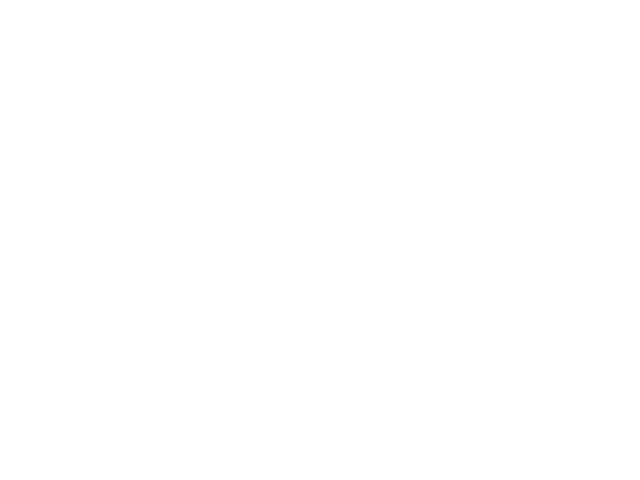

<IPython.core.display.Javascript object>


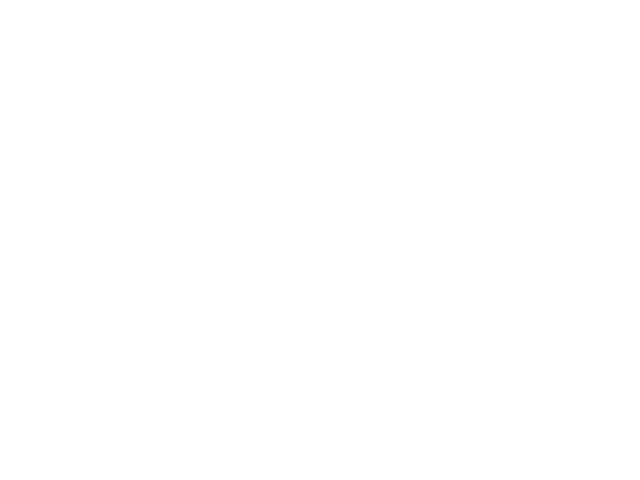

In [16]:
# --------------------------------------------
# --- SCAN on EPS: compare source Q ---
# --------------------------------------------
idx_point = vars_cl['ids-Q'][1] 

fig = plt.figure(); ax = fig.add_subplot(111)
ax.plot(
    t_scan*beta, np.real(Q_eps7[idx_point,:]/beta), 
    color='black', linewidth = 2, linestyle='-', label = "$eps = 1e-7$"
)
ax.plot(
    t_scan*beta, np.real(Q[idx_point,0:nt_scan]/beta), 
    color='b', linewidth = 2, linestyle='--', label = "$eps = 1e-6$"
)
ax.plot(
    t_scan*beta, np.real(Q_eps5[idx_point,:]/beta), 
    color='r', linewidth = 2, linestyle='--', label = "$eps = 1e-5$"
)
ax.plot(
    t_scan*beta, np.real(Q_eps4[idx_point,:]/beta), 
    color='g', linewidth = 2, linestyle='--', label = "$eps = 1e-4$"
)
plt.xlabel('$t$'); plt.ylabel("$real[Q]$"); ax.legend(); plt.grid(True); plt.show()
plt.savefig(path_fig + 'Q-scan-eps-real.png')


fig = plt.figure(); ax = fig.add_subplot(111)
ax.plot(
    t_scan*beta, np.imag(Q_eps7[idx_point,:]/beta), 
    color='black', linewidth = 2, linestyle='-', label = "$eps = 1e-7$"
)
ax.plot(
    t_scan*beta, np.imag(Q[idx_point,0:nt_scan]/beta), 
    color='b', linewidth = 2, linestyle='--', label = "$eps = 1e-6$"
)
ax.plot(
    t_scan*beta, np.imag(Q_eps5[idx_point,:]/beta), 
    color='r', linewidth = 2, linestyle='--', label = "$eps = 1e-5$"
)
ax.plot(
    t_scan*beta, np.imag(Q_eps4[idx_point,:]/beta), 
    color='g', linewidth = 2, linestyle='--', label = "$eps = 1e-4$"
)
plt.xlabel('$t$'); plt.ylabel("$imag[Q]$"); ax.legend(); plt.grid(True); plt.show()
plt.savefig(path_fig + 'Q-scan-eps-imag.png')

In [17]:
# --- SCAN-EPS: get amplitudes of a variable ---
reload(xw)
def get_W(dd_loc, Q_loc):
    vx_loc = mse.get_amplitudes_xt(dd_loc, {"d": 0}, "j")
    vy_loc = mse.get_amplitudes_xt(dd_loc, {"d": 1}, "j")
    Ex_loc = mse.get_amplitudes_xt(dd_loc, {"d": 2}, "j")
    Ey_loc = mse.get_amplitudes_xt(dd_loc, {"d": 3}, "j")
    Bz_loc = mse.get_amplitudes_xt(dd_loc, {"d": 4}, "j")

    Wv_loc = np.abs(vx_loc)**2 + np.abs(vy_loc)**2
    We_loc = np.abs(Ex_loc)**2 + np.abs(Ey_loc)**2
    Wb_loc = np.abs(Bz_loc)**2
    Wq_loc = np.abs(Q_loc)**2
    W_loc = Wv_loc + We_loc + Wb_loc + Wq_loc
    print("one case is formed")
    return W_loc

W_eps7 = get_W(dd_eps7, Q_eps7)
W_eps5 = get_W(dd_eps5, Q_eps5)
W_eps4 = get_W(dd_eps4, Q_eps4)

one case is formed
one case is formed
one case is formed


In [18]:
# -------------------------------------------------------------------
# --- SCAN-EPS: Calculate energy integrated in space ---
# -------------------------------------------------------------------
Wt_eps7 = np.array([np.sum(W_eps7[:,i]) for i in range(nt_scan)])
Wt_eps5 = np.array([np.sum(W_eps5[:,i]) for i in range(nt_scan)])
Wt_eps4 = np.array([np.sum(W_eps4[:,i]) for i in range(nt_scan)])

<IPython.core.display.Javascript object>


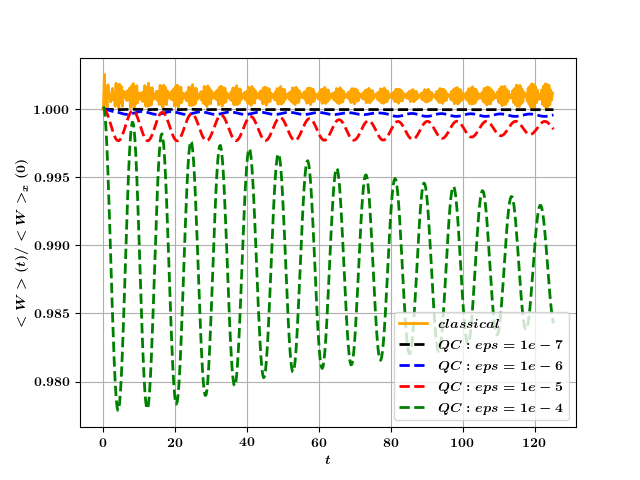

In [20]:
# ----------------------------------------------------------------------------------
# --- SCAN-EPS: Compare energy integrated in space ---
# ----------------------------------------------------------------------------------
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(
    t_cl[0:nt_scan], Wt_cl[0:nt_scan]/Wt_cl[1], 
    color='orange', 
    linewidth = 2, linestyle='-',
    label = "$classical$" 
)
ax.plot(t_scan*beta, Wt_eps7[0:nt_scan]/Wt_eps7[1], 
        color='black', linewidth = 2, linestyle='--', label = "$QC: eps=1e-7$")
ax.plot(t_scan*beta, Wt[0:nt_scan]/Wt[1], 
        color='b', linewidth = 2, linestyle='--', label = "$QC: eps=1e-6$")
ax.plot(t_scan*beta, Wt_eps5[0:nt_scan]/Wt_eps5[1], 
        color='r', linewidth = 2, linestyle='--', label = "$QC: eps=1e-5$")
ax.plot(t_scan*beta, Wt_eps4[0:nt_scan]/Wt_eps4[1], 
        color='g', linewidth = 2, linestyle='--', label = "$QC: eps=1e-4$")
plt.xlabel('$t$')
plt.ylabel("$<W>(t)/<W>_x(0)$")
ax.legend()
plt.grid(True)
plt.show()
plt.savefig(path_fig +'-W-scan.png')

In [17]:
# -------------------------------------------------------------------
# --- SAVE PLOTS: W-total: scan on eps ---
# -------------------------------------------------------------------
reload(xw)

# # save W-esp6 profile
# full_fname = path_results + "/W-full-eps6.dat"
# mix.save_dat_plot_1d_file(full_fname, t_scan*beta, Wt[0:nt_scan]/Wt[1])

# # save W-esp7 profile
# full_fname = path_results + "/W-full-eps7.dat"
# mix.save_dat_plot_1d_file(full_fname, t_scan*beta, Wt_eps7/Wt_eps7[1])

# # save W-esp5 profile
# full_fname = path_results + "/W-full-eps5.dat"
# mix.save_dat_plot_1d_file(full_fname, t_scan*beta, Wt_eps5/Wt_eps5[1])

# # save W-esp4 profile
# full_fname = path_results + "/W-full-eps4.dat"
# mix.save_dat_plot_1d_file(full_fname, t_scan*beta, Wt_eps4/Wt_eps4[1])

# save W-classical profile
full_fname = path_results + "/W-full-classical.dat"
mix.save_dat_plot_1d_file(full_fname, t_cl[0:nt_scan], Wt_cl[0:nt_scan]/Wt_cl[1])

write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-full-classical.dat


In [26]:
# -------------------------------------------------------------------
# --- SAVE PLOTS: Q ---
# -------------------------------------------------------------------
reload(xw)

idx_point = vars_cl['ids-Q'][1] 

# save Q-classical
full_fname = path_results + "/Q-classical-real-t.dat"
mix.save_dat_plot_1d_file(full_fname, t_cl[0:len(t)], np.real(Q_cl[idx_point,0:len(t)]))
full_fname = path_results + "/Q-classical-imag-t.dat"
mix.save_dat_plot_1d_file(full_fname, t_cl[0:len(t)], np.imag(Q_cl[idx_point,0:len(t)]))

# save Q-quantum
full_fname = path_results + "/Q-qc-real-t.dat"
mix.save_dat_plot_1d_file(full_fname, t*beta, np.real(Q[idx_point,:])/beta)
full_fname = path_results + "/Q-qc-imag-t.dat"
mix.save_dat_plot_1d_file(full_fname, t*beta, np.imag(Q[idx_point,:])/beta)

write data to a file: ./QSP/examples/XW_1D/ref-case/results//Q-classical-real-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//Q-classical-imag-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//Q-qc-real-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//Q-qc-imag-t.dat


In [29]:
# -------------------------------------------------------------------
# --- SAVE PLOTS: W-components (t) ---
# -------------------------------------------------------------------
reload(xw)

# save W-components classical 
full_fname = path_results + "/W-kin-classical-t.dat"
mix.save_dat_plot_1d_file(full_fname, t_cl, Wt_v_cl/Wt_cl[1])
full_fname = path_results + "/W-field-classical-t.dat"
mix.save_dat_plot_1d_file(full_fname, t_cl, (Wt_e_cl + Wt_b_cl)/Wt_cl[1])
full_fname = path_results + "/W-q-classical-t.dat"
mix.save_dat_plot_1d_file(full_fname, t_cl, Wt_q_cl/Wt_cl[1])

# save W-components QC 
full_fname = path_results + "/W-kin-qc-t.dat"
mix.save_dat_plot_1d_file(full_fname, t*beta, Wt_v/Wt[1])
full_fname = path_results + "/W-field-qc-t.dat"
mix.save_dat_plot_1d_file(full_fname, t*beta, (Wt_e + Wt_b)/Wt[1])
full_fname = path_results + "/W-q-qc-t.dat"
mix.save_dat_plot_1d_file(full_fname, t*beta, Wt_q/Wt[1])

write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-kin-classical-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-field-classical-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-q-classical-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-kin-qc-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-field-qc-t.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-q-qc-t.dat


In [37]:
# -------------------------------------------------------------------
# --- SAVE PLOTS: W-kin (x, t-last) ---
# -------------------------------------------------------------------
reload(xw)

# save W-kin classical 
full_fname = path_results + "/W-kin-classical-x.dat"
mix.save_dat_plot_1d_file(full_fname, x_cl, Wv_cl[:,len(t)-1])

# save W-kin QC 
full_fname = path_results + "/W-kin-qc-x.dat"
mix.save_dat_plot_1d_file(full_fname, x_qc, Wv[:,-1]/beta**2)

write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-kin-classical-x.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-kin-qc-x.dat


In [26]:
# -------------------------------------------------------------------
# --- SAVE PLOTS: W-field (x, t-last) ---
# -------------------------------------------------------------------
reload(xw)

# save W-field classical 
full_fname = path_results + "/W-field-classical-x.dat"
mix.save_dat_plot_1d_file(full_fname, x_cl, (We_cl[:,len(t)-1] + Wb_cl[:,len(t)-1]))

# save W-field QC 
full_fname = path_results + "/W-field-qc-x.dat"
mix.save_dat_plot_1d_file(full_fname, x_qc, (We[:,-1] + Wb[:,-1])/beta**2)

write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-field-classical-x.dat
write data to a file: ./QSP/examples/XW_1D/ref-case/results//W-field-qc-x.dat
